# Interpret statement response functions

Compare how forced-choice statements relate to one trait. An overlay makes
differences in slopes and locations easy to see. A separate panel for each
statement makes overlapping curves easier to read.

The six plotted forced-choice models come from a joint simulation with
128 respondents and three traits. Each curve evaluates its response function
at the posterior mean parameters.

## Keep utility and endorsement separate

The horizontal axis is the score $\theta$ on the trait assigned to
statement $j$. Let $a_j>0$ be the statement's discrimination and let
$q_j\in\{-1,+1\}$ be the keying sign for a dominance model.

Four models show **utility** on the vertical axis:

$$
\begin{aligned}
m_j(\theta)&=\nu_j+q_j a_j\theta &&\text{(TIRT)},\\
m_j(\theta)&=\alpha_j+q_j a_j\theta &&\text{(TIRTRank)},\\
u_j(\theta)&=q_j a_j\theta-b_j &&\text{(MGPPM)},\\
m_j(\theta)&=-a_j|\theta-\delta_j| &&\text{(GTUM)}.
\end{aligned}
$$

A positive keying sign gives an increasing line, and negative keying gives
a decreasing line. The statement effect $\nu_j$, the ranking intercept
$\alpha_j$ and the subtractive intercept $b_j$ shift their respective
curves vertically. GTUM utility is highest at the ideal point $\delta_j$.

2PLM-RANK and GGUM-RANK show **statement endorsement probability**.
For 2PLM-RANK the log endorsement odds are $\ell_j=q_j a_j\theta-b_j$.
For GGUM-RANK, with $x_j=a_j(\theta-\delta_j)$ and statement threshold
$\tau_j$, they are

$$
\ell_j=\log(e^{x_j}+e^{2x_j})-a_j\tau_j-\log(1+e^{3x_j}).
$$

Both probabilities are $e_j(\theta)=1/(1+e^{-\ell_j})$. Increasing $\tau_j$
lowers the GGUM-RANK curve. Moving equally far above or below $\delta_j$
gives the same endorsement probability. In a forced-choice block, the
successive-choice models use the odds $e^{\ell_j}$ relative to the other
available statements. The plotted curves describe one statement at a time.

Each curve uses the statement's posterior mean parameters. The next cells
load those estimates and evaluate the functions over a grid of trait scores.

## Read the fitted estimates

Save the [statement parameters](../_static/gallery/statement_curves_parameters.csv)
and [posterior mean scores](../_static/gallery/statement_curves_scores.csv)
in the notebook's working directory. Each parameter row identifies a
model, statement and trait. Each score row contains a fitted respondent
score for one trait.

In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from jax.nn import sigmoid

sns.set_theme(style="ticks")


parameters = pd.read_csv("statement_curves_parameters.csv")
score_means = pd.read_csv("statement_curves_scores.csv")
columns = [
    "model",
    "statement",
    "trait",
    "loading_magnitude",
    "location",
]
parameters.loc[parameters.model.eq("GTUM"), columns].head(3).round(2)

,model,statement,trait,loading_magnitude,location
40,GTUM,GTUM_B1|S1,agency,0.98,2.43
41,GTUM,GTUM_B1|S2,communion,0.91,-2.08
42,GTUM,GTUM_B2|S1,agency,0.93,-2.48


In [2]:
def statement_curves(parameters, theta):
    """Evaluate model equations at final, posterior-mean statement parameters."""
    frames = []
    for model, rows in parameters.groupby("model", sort=False):
        a = jnp.asarray(rows.loading_magnitude.values)[:, None]
        q = jnp.asarray(rows.keying.values)[:, None]
        t = jnp.asarray(theta)[None, :]
        endorsement = model in {"TwoPLRank", "GGUMRank"}
        if model in {"MGPPM", "TwoPLRank"}:
            utility = q * a * t - jnp.asarray(rows.intercept.values)[:, None]
        elif model == "TIRT":
            utility = q * a * t + jnp.asarray(rows.statement_effect.values)[:, None]
        elif model == "TIRTRank":
            utility = q * a * t + jnp.asarray(rows.intercept.values)[:, None]
        elif model == "GTUM":
            utility = -a * jnp.abs(t - jnp.asarray(rows.location.values)[:, None])
        elif model == "GGUMRank":
            x = a * (t - jnp.asarray(rows.location.values)[:, None])
            utility = (
                jnp.logaddexp(x, 2 * x)
                - a * jnp.asarray(rows.threshold.values)[:, None]
                - jnp.logaddexp(0, 3 * x)
            )
        else:
            raise ValueError(f"Unknown model: {model}")
        values = sigmoid(utility) if endorsement else utility
        for i, (_, row) in enumerate(rows.iterrows()):
            frames.append(
                pd.DataFrame(
                    {
                        "model": model,
                        "statement": row.statement,
                        "trait": row.trait,
                        "theta": theta,
                        "value": values[i],
                        "location": row.location,
                        "scale": "endorsement" if endorsement else "utility",
                        "value_at_location": (
                            float(sigmoid(-row.loading_magnitude * row.threshold))
                            if model == "GGUMRank"
                            else 0.0
                        ),
                    }
                )
            )
    return pd.concat(frames, ignore_index=True)


curves = statement_curves(parameters, jnp.linspace(-3, 3, 121))

## Compare statements on one trait

All three plots use agency as the horizontal axis. Each line shows one
statement. In the overlay, dots mark the displayed ideal points.
The ticks along the axis mark the respondents' posterior mean scores.
The gray band spans the middle 90% of those scores.

In [3]:
agency_curves = curves.loc[curves.trait.eq("agency")]
agency_scores = score_means.loc[score_means.trait.eq("agency"), "score_mean"]
low, high = agency_scores.quantile([0.05, 0.95])
gtum_curves = agency_curves.loc[agency_curves.model.eq("GTUM")]

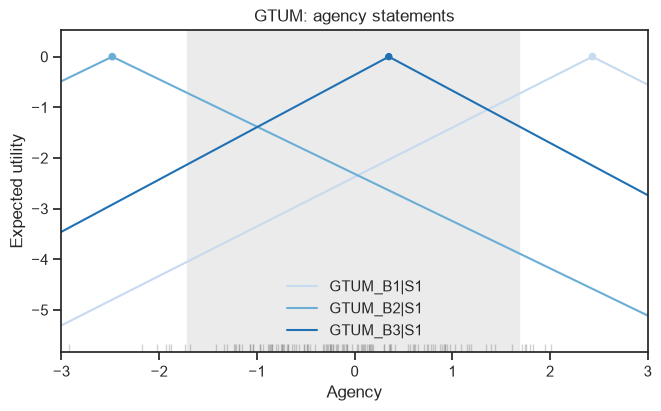

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
ax.axvspan(low, high, color="0.92")
sns.lineplot(
    data=gtum_curves,
    x="theta",
    y="value",
    hue="statement",
    palette="Blues",
    ax=ax,
)
peaks = gtum_curves.drop_duplicates("statement")
sns.scatterplot(
    data=peaks,
    x="location",
    y="value_at_location",
    hue="statement",
    palette="Blues",
    legend=False,
    ax=ax,
)
sns.rugplot(x=agency_scores, color="0.4", alpha=0.3, ax=ax)
ax.set(
    xlabel="Agency",
    ylabel="Expected utility",
    title="GTUM: agency statements",
    xlim=(-3, 3),
)
ax.legend(title=None, frameon=False)
plt.show()

GTUM utility peaks at the statement's location and falls away from it.
B1/S1 and B2/S1 peak outside the central 90% of fitted scores. B3/S1 peaks
inside that range. When curves overlap, give each statement its own panel.

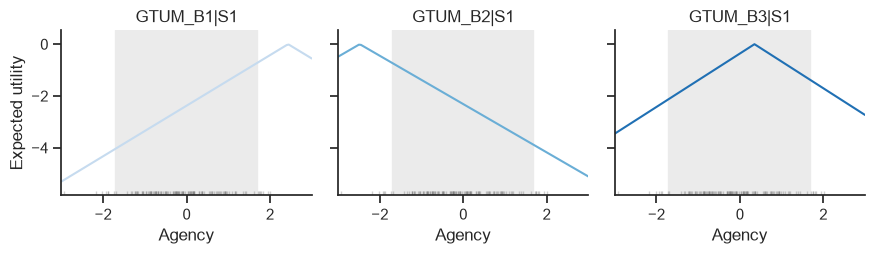

In [5]:
grid = sns.relplot(
    data=gtum_curves,
    x="theta",
    y="value",
    hue="statement",
    col="statement",
    col_wrap=3,
    kind="line",
    palette="Blues",
    height=2.7,
    aspect=1.1,
    legend=False,
)
for ax in grid.axes.flat:
    ax.axvspan(low, high, color="0.92", zorder=0)
    sns.rugplot(x=agency_scores, color="0.4", alpha=0.3, ax=ax)
grid.set(xlabel="Agency", ylabel="Expected utility", xlim=(-3, 3))
grid.set_titles("{col_name}")
plt.show()

## Read the differences across response laws

Use the shape of each curve to see how the statement relates to agency.
Utility and endorsement have different scales, so compare numerical
heights within each panel.

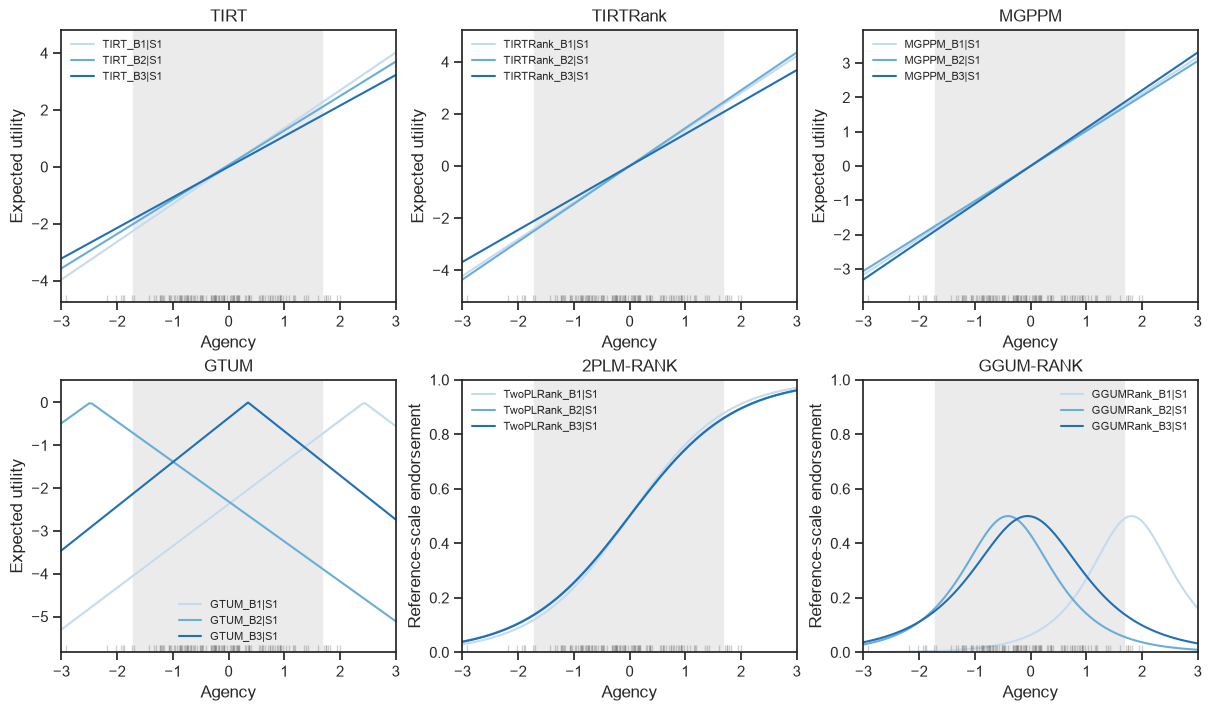

In [6]:
titles = {
    "TIRT": "TIRT",
    "TIRTRank": "TIRTRank",
    "MGPPM": "MGPPM",
    "GTUM": "GTUM",
    "TwoPLRank": "2PLM-RANK",
    "GGUMRank": "GGUM-RANK",
}
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, (family, title) in zip(axes.flat, titles.items(), strict=True):
    selected = agency_curves.loc[agency_curves.model.eq(family)]
    ax.axvspan(low, high, color="0.92", zorder=0)
    sns.lineplot(
        data=selected,
        x="theta",
        y="value",
        hue="statement",
        palette="Blues",
        ax=ax,
    )
    sns.rugplot(x=agency_scores, color="0.4", alpha=0.3, ax=ax)
    endorsement = family in {"TwoPLRank", "GGUMRank"}
    ax.set(
        title=title,
        xlabel="Agency",
        xlim=(-3, 3),
        ylabel="Reference-scale endorsement" if endorsement else "Expected utility",
    )
    if endorsement:
        ax.set_ylim(0, 1)
    ax.legend(title=None, frameon=False, fontsize=8)
plt.show()

TIRT, TIRTRank and MGPPM show linear utilities. GTUM and GGUM-RANK show
ideal-point peaks. The shared crossings in some panels come from their
reference intercepts. The fitted slopes can still differ.

For your own fit, [coef()](../reference/generated/pyfcirt.coef.md) reports
parameters by statement. The model's [predictive checks](../reference/prediction.md)
compare the implied responses with the observed choices.